# Compare Subspace:

SHOULD BE:
- set the parameters

- Run `vs3_0_transformation.py` 

- Run `vs3_0_clustering.py` get the ones in vs3_1 as a complement (TODO try maybe other methods)

- Run `vs3_0_spatial_clouds.py`

- Run `vs3_0_weights_stability`: stability of the spatial pattern when changing the pairing -- plot result in section 1





In [1]:
from pathlib import Path
import json
import sys
import pandas as pd
from IPython.display import display, Image

ROOT = Path.cwd()
if not (ROOT / 'compare_subspace.py').exists() and (ROOT / 'iEEGvsMEG' / 'compare_subspace.py').exists():
    ROOT = ROOT / 'iEEGvsMEG'
sys.path.insert(0, str(ROOT))
from vs3_0_compare_subspace import load_results, plot_results

MEG_KIND = 'paired_coverage'  # full_average, full_concatenated, coverage_average, paired_coverage, random_control
OUTPUT_DIR = ROOT / 'out' / 'compare_subspace' / MEG_KIND
DISPLAY_K = 10

## Run the analysis
```bash
submit_to_cluster -n 2 -q long.q "python -u compare_subspace.py --meg-kind paired_coverage --models separate_pca plssvd joint_pca --dimensions 1 2 3 5 10 --n-splits 5 --block-scaling equal_variance --ridge-alpha 0.01" --project MINDLAB2021_MEG-TempSeqAges
```

In [2]:
config, tables = load_results(OUTPUT_DIR)
if config.get('schema_version', 1) < 2:
    raise ValueError('Run the updated analysis into a new directory: these outputs use the old split design.')
display(pd.Series(config, name='Run configuration'))
# Full-data fit first: descriptive scores, not testing or an upper bound.
for name in ('overlap', 'alignment', 'clusters'):
    print(f'All-data description: {name}')
    display(tables[name].query("partition == 'in_sample' and k == @DISPLAY_K"))
plot_results(OUTPUT_DIR, k=DISPLAY_K, show=False)


schema_version                                                             3
cloud_prototypes                                                          32
condition_mode                                                       average
full_data_repeat                                                          -1
cache_dir                  /users/barbara/Desktop/MIB_iEEG/iEEGvsMEG/out/...
meg_kind                                                     paired_coverage
models                                     [separate_pca, plssvd, joint_pca]
dimensions                                                  [1, 2, 3, 5, 10]
repeats                                                                    5
seed                                                                    2026
block_scaling                                                 equal_variance
split_unit                                                             trial
cluster_counts                                               [2, 3, 4, 5, 6]

All-data description: overlap


,analysis,model,repeat,k,space,partition,overlap,rank_a,rank_b,angles_deg
8,in_sample,separate_pca,-1,10,temporal_scores,in_sample,0.670573,10,10,"[11.247152543052204, 15.29611633763942, 19.394..."
9,in_sample,separate_pca,-1,10,spatial_patterns,in_sample,0.002288,10,10,"[84.78964867503421, 85.8658325359956, 86.88170..."
18,in_sample,plssvd,-1,10,temporal_scores,in_sample,0.866401,10,10,"[10.850754785380301, 14.117590846071495, 16.05..."
19,in_sample,plssvd,-1,10,spatial_patterns,in_sample,0.002376,10,10,"[84.6097612968945, 86.14477219161705, 86.89909..."
28,in_sample,joint_pca,-1,10,temporal_scores,in_sample,0.817937,10,10,"[9.946348155907437, 14.359040688160189, 17.027..."
29,in_sample,joint_pca,-1,10,spatial_patterns,in_sample,0.002208,10,10,"[84.75705239181605, 86.12592326933905, 87.0534..."


All-data description: alignment


,analysis,model,repeat,k,space,direction,complexity,partition,alpha,nrmse,q2
64,in_sample,separate_pca,-1,10,temporal_scores,ieeg_to_meg,identity,in_sample,0.00,1.038523,-0.078529
65,in_sample,separate_pca,-1,10,temporal_scores,ieeg_to_meg,orthogonal,in_sample,0.00,0.655684,0.570079
66,in_sample,separate_pca,-1,10,temporal_scores,ieeg_to_meg,affine,in_sample,0.01,0.503069,0.746922
67,in_sample,separate_pca,-1,10,temporal_scores,ieeg_to_meg,quadratic,in_sample,0.01,0.319311,0.898040
68,in_sample,separate_pca,-1,10,temporal_scores,meg_to_ieeg,identity,in_sample,0.00,1.038523,-0.078529
69,in_sample,separate_pca,-1,10,temporal_scores,meg_to_ieeg,orthogonal,in_sample,0.00,0.655684,0.570079
70,in_sample,separate_pca,-1,10,temporal_scores,meg_to_ieeg,affine,in_sample,0.01,0.390317,0.847653
71,in_sample,separate_pca,-1,10,temporal_scores,meg_to_ieeg,quadratic,in_sample,0.01,0.220002,0.951599
72,in_sample,separate_pca,-1,10,spatial_patterns,ieeg_to_meg,identity,in_sample,0.00,1.410792,-0.990333
73,in_sample,separate_pca,-1,10,spatial_patterns,ieeg_to_meg,orthogonal,in_sample,0.00,1.385800,-0.920440


All-data description: clusters


,analysis,model,repeat,k,metric,modality,partition,value,n_clusters
60,in_sample,separate_pca,-1,10,cross_modal_ari,both,in_sample,-0.000277,2
61,in_sample,separate_pca,-1,10,silhouette,ieeg,in_sample,0.072580,2
62,in_sample,separate_pca,-1,10,silhouette,meg,in_sample,0.074476,2
63,in_sample,separate_pca,-1,10,cross_modal_ari,both,in_sample,-0.000318,3
64,in_sample,separate_pca,-1,10,silhouette,ieeg,in_sample,0.062545,3
65,in_sample,separate_pca,-1,10,silhouette,meg,in_sample,0.075071,3
66,in_sample,separate_pca,-1,10,cross_modal_ari,both,in_sample,0.000424,4
67,in_sample,separate_pca,-1,10,silhouette,ieeg,in_sample,0.064756,4
68,in_sample,separate_pca,-1,10,silhouette,meg,in_sample,0.083330,4
69,in_sample,separate_pca,-1,10,cross_modal_ari,both,in_sample,0.000941,5


['/users/barbara/Desktop/MIB_iEEG/iEEGvsMEG/out/compare_subspace/paired_coverage/subspace_overlap.png',
 '/users/barbara/Desktop/MIB_iEEG/iEEGvsMEG/out/compare_subspace/paired_coverage/alignment_complexity_k10.png',
 '/users/barbara/Desktop/MIB_iEEG/iEEGvsMEG/out/compare_subspace/paired_coverage/cluster_agreement_k10.png',
 '/users/barbara/Desktop/MIB_iEEG/iEEGvsMEG/out/compare_subspace/paired_coverage/fold_consistency_k10.png',
 '/users/barbara/Desktop/MIB_iEEG/iEEGvsMEG/out/compare_subspace/paired_coverage/unpaired_cloud_distances.png']

## 1. Subspace overlap
Principal-angle overlap compares the full retained spaces, permitting axis rotations/mixing. One means identical full-rank spaces and zero means orthogonal. Missing dimensions count as zero. Temporal and spatial similarity answer separate questions.

Dashed lines: all-data in-sample description. Solid lines: test-fold median. Shading: fold minimum–maximum, not confidence intervals.

Temporal comparisons use shared time points, with no electrode pairing. Spatial overlap, transformation and original ARI use corresponding feature rows: full_concatenated selects them using the seeded participant pairing and nearest-source map. These are not full-cloud spatial comparisons.


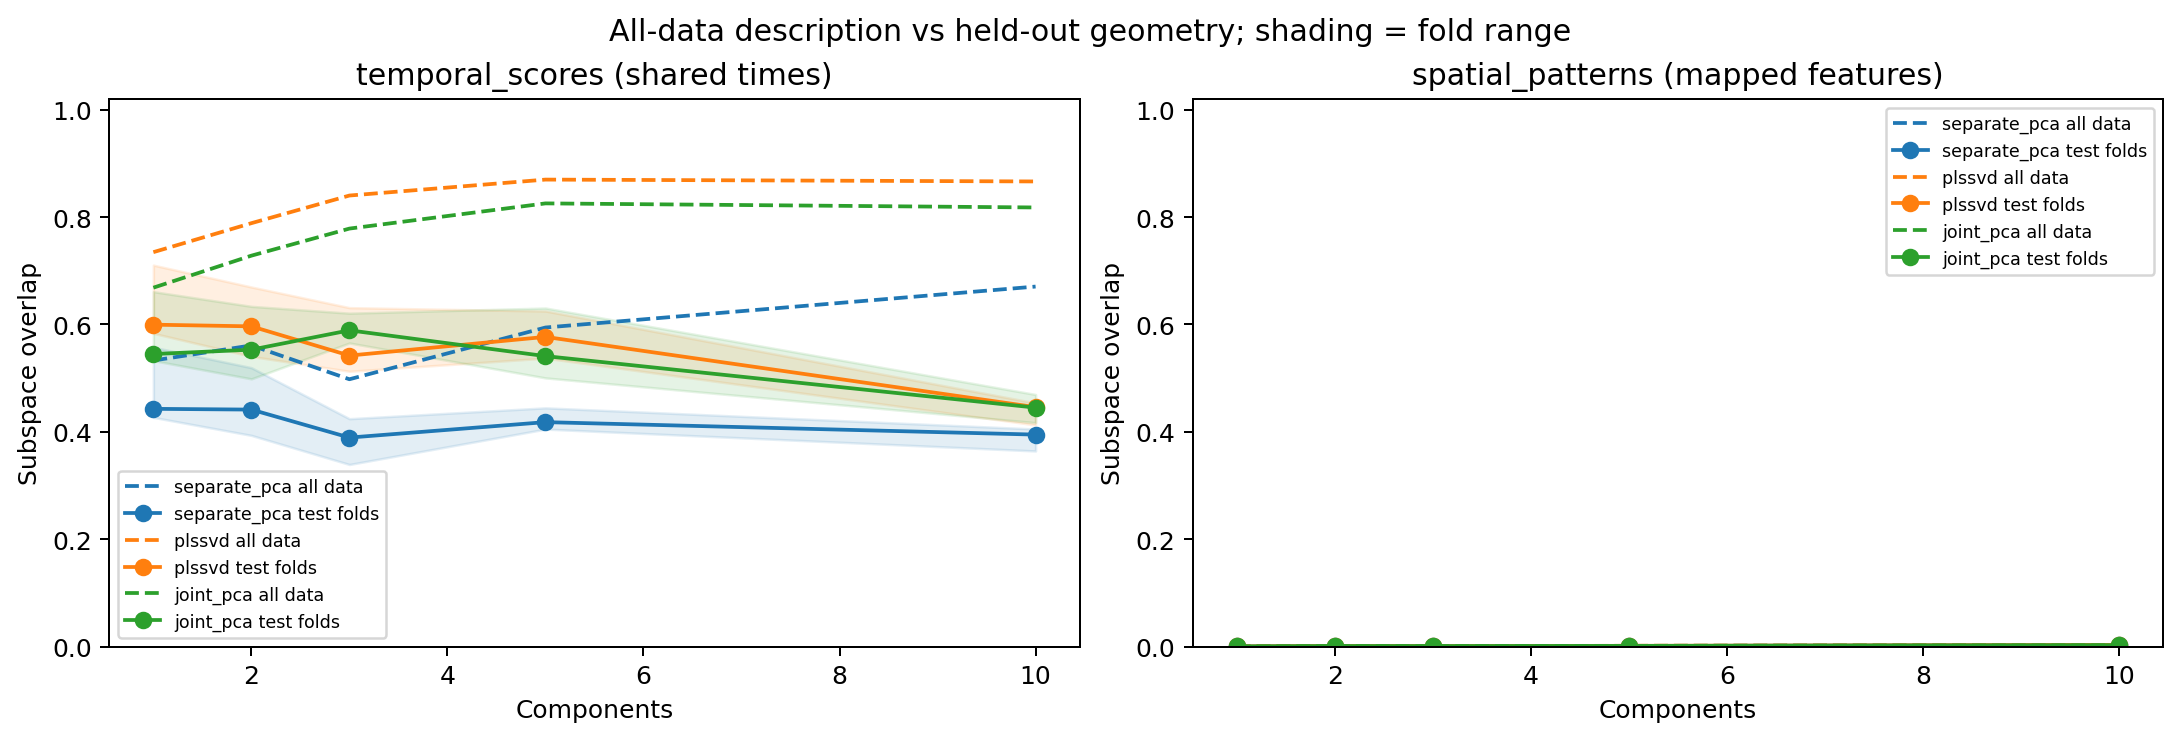

,model,repeat,space,k,overlap,rank_a,rank_b,angles_deg
30,separate_pca,0,temporal_scores,1,0.557556,1,1,[41.69494355504188]
32,separate_pca,0,spatial_patterns,1,0.000119,1,1,[89.3762773614969]
34,separate_pca,0,temporal_scores,2,0.510401,2,2,"[41.68496019633413, 47.11771406705361]"
36,separate_pca,0,spatial_patterns,2,0.000414,2,2,"[88.49859700827174, 89.31737155891281]"
38,separate_pca,0,temporal_scores,3,0.424379,3,3,"[27.841803613968555, 46.919979384499136, 80.95..."
...,...,...,...,...,...,...,...,...
320,joint_pca,4,spatial_patterns,3,0.000474,3,3,"[88.07196352198834, 89.11924407377195, 89.5791..."
322,joint_pca,4,temporal_scores,5,0.575597,5,5,"[25.69463570805392, 31.542166166067283, 42.825..."
324,joint_pca,4,spatial_patterns,5,0.001118,5,5,"[86.76654333897342, 87.6816332110351, 88.57558..."
326,joint_pca,4,temporal_scores,10,0.463372,10,10,"[21.07012559565514, 26.41231820741519, 36.8374..."


In [3]:
display(Image(filename=str(OUTPUT_DIR / 'subspace_overlap.png')))
display(tables['overlap'].query("partition == 'test'")[
    ['model', 'repeat', 'space', 'k', 'overlap', 'rank_a', 'rank_b', 'angles_deg']])


## 2. Transformation generalization
Training means and one scalar RMS normalize each modality's representation. Fit identity, orthogonal, affine and quadratic maps in both directions. Ridge is fixed beforehand (default 0.01); no tuning. Apply each map unchanged to held-out responses.

NRMSE below 1 beats the training-mean baseline; Q² = 1 − NRMSE². Dashed all-data results are descriptive; use test-fold errors to assess generalization. Time points and locations recur across partitions.

Temporal comparisons use shared time points, with no electrode pairing. Spatial overlap, transformation and original ARI use corresponding feature rows: full_concatenated selects them using the seeded participant pairing and nearest-source map. These are not full-cloud spatial comparisons.


- Identity	Nothing beyond the preceding training-based centering and overall scaling
- Orthogonal	Component signs, order, rotation and reflection; preserves distances
- Affine	Also allows unequal scaling and general linear mixing
- Quadratic	Adds squared coordinates and interactions between coordinates

| Error | Interpretation |
|---|---|
| \(0\) | Perfect prediction |
| \(0.7\) | Squared prediction error is 49% of the baseline error; \(Q^2=0.51\) |
| \(1\) | No improvement over predicting the target’s training mean |
| \(>1\) | Worse than predicting that mean |

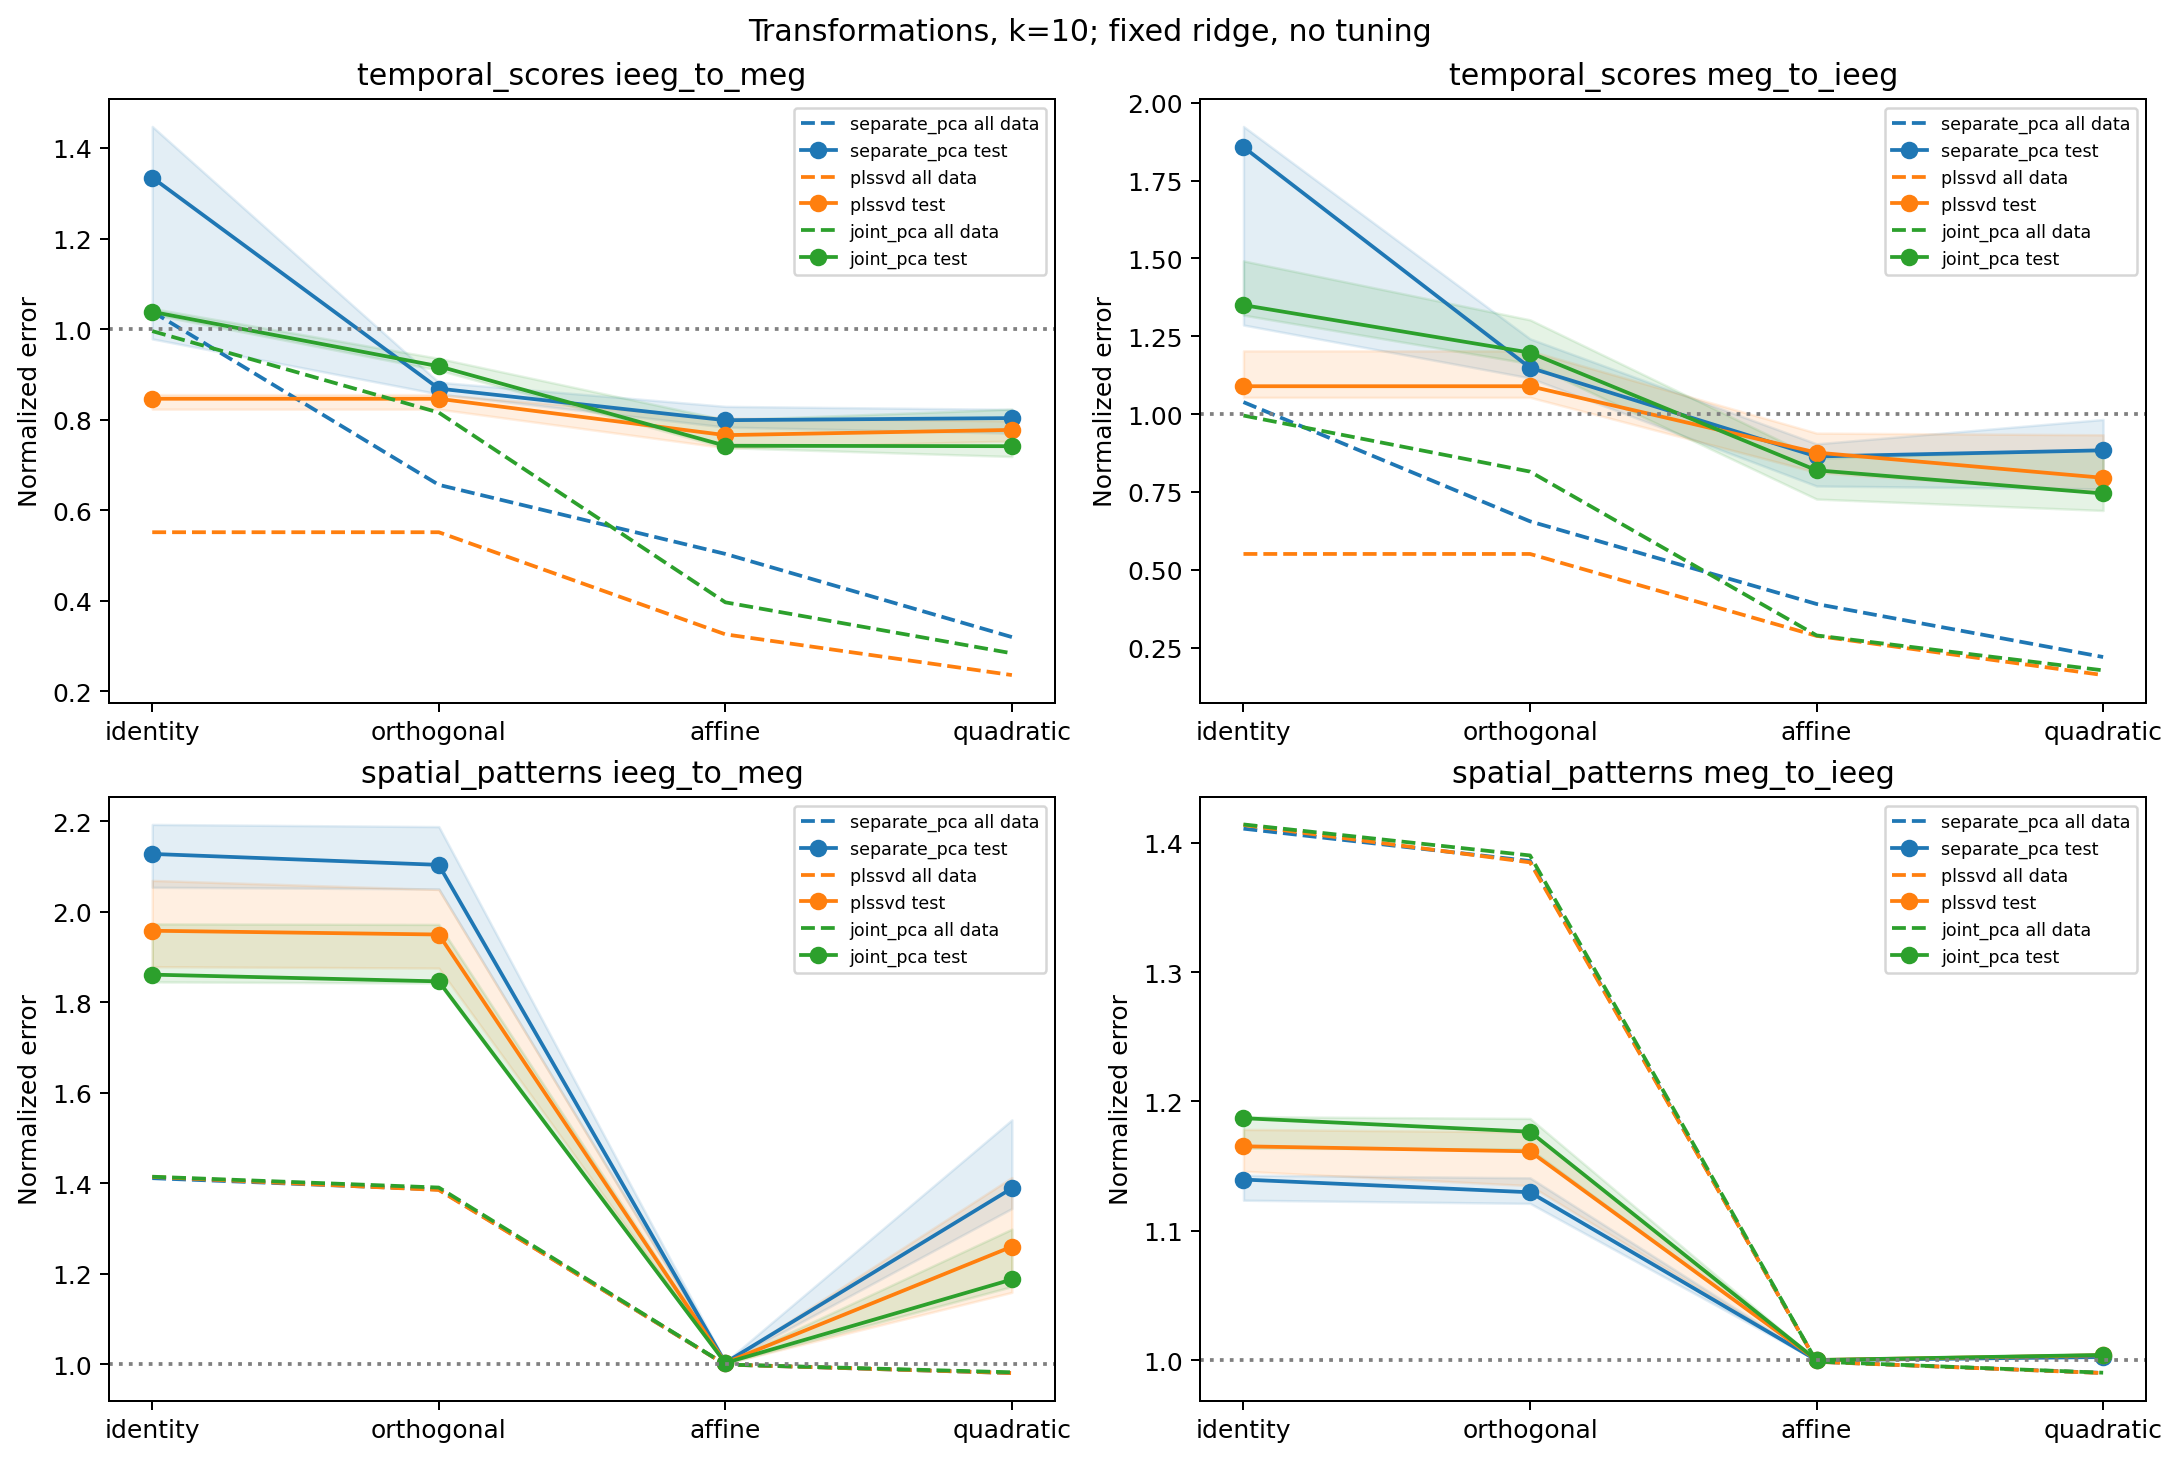

In [4]:
display(Image(filename=str(OUTPUT_DIR / f'alignment_complexity_k{DISPLAY_K}.png')))
#display(tables['alignment'].query("partition == 'test' and k == @DISPLAY_K")[['model', 'repeat', 'space', 'direction', 'complexity', 'alpha', 'nrmse', 'q2']])


## 3. Exploratory spatial grouping
K-means is fitted separately to each modality's training spatial patterns. All predeclared cluster counts are reported; none is selected using test agreement. Held-out patterns are assigned to training centroids. ARI compares cross-modal membership and silhouette describes compactness/separation. No test-half stability is computed. Stable groups do not by themselves establish biological networks.

ARI essentially asks whether pairs of locations are grouped together or separated consistently between modalities, with a correction for chance agreement.
- 1: identical partitions.
- Around 0: agreement near the chance-adjusted reference.
- Negative: less agreement than that reference.


Pairwise cluster.
Temporal comparisons use shared time points, with no electrode pairing. Spatial overlap, transformation and original ARI use corresponding feature rows: full_concatenated selects them using the seeded participant pairing and nearest-source map. These are not full-cloud spatial comparisons.


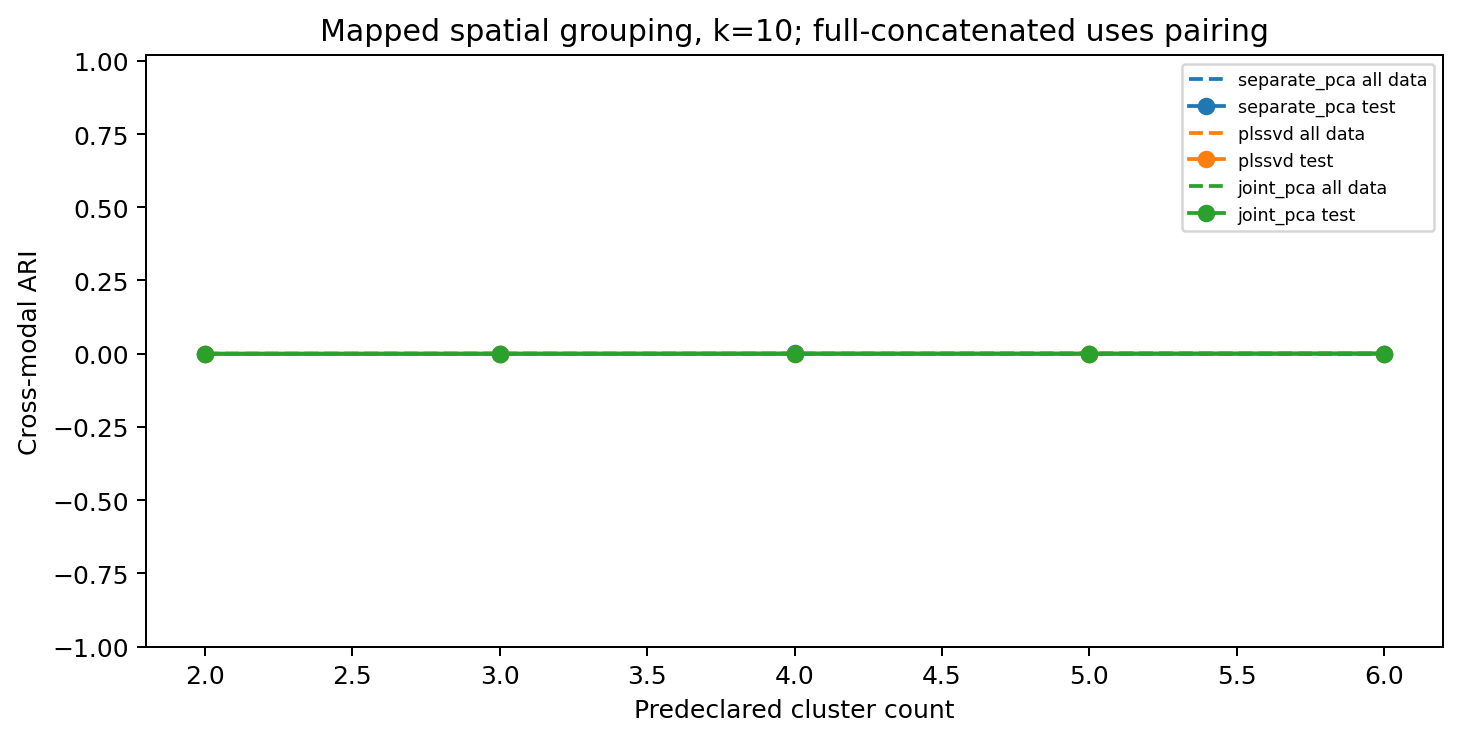

In [5]:
display(Image(filename=str(OUTPUT_DIR / f'cluster_agreement_k{DISPLAY_K}.png')))
#display(tables['clusters'].query("partition == 'test' and k == @DISPLAY_K"))


### Full-data 3D component-space clusters
For each model, view two side-by-side iEEG/MEG figures: (1) choose the highest full-data silhouette separately in each modality; (2) choose the common count with highest full-data cross-modal ARI. Both are descriptive choices among the saved candidate counts, with ties favoring fewer clusters. ARI compares separate clusterings; no joint K-means is fitted.
Points are electrodes/mapped sources represented by their three spatial forward-pattern coefficients, centered and uniformly scaled using the saved training normalization. Brain x/y/z are not used. X marks centroids. The ARI view matches cluster colours by membership agreement. Same colours need not mean identical membership, and component axes have not been aligned across modalities.
Requires full-data k=3 artifacts from the completed analysis; no refitting is needed. Exports PNG/PDF and a descriptive selection table under `full_data_clusters_3d/`.


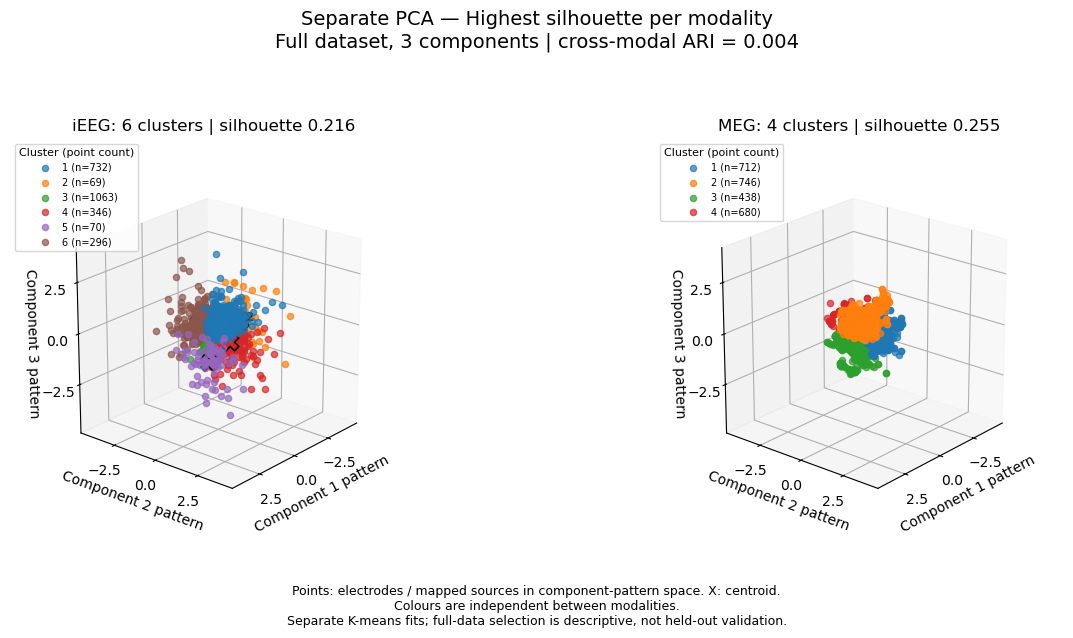

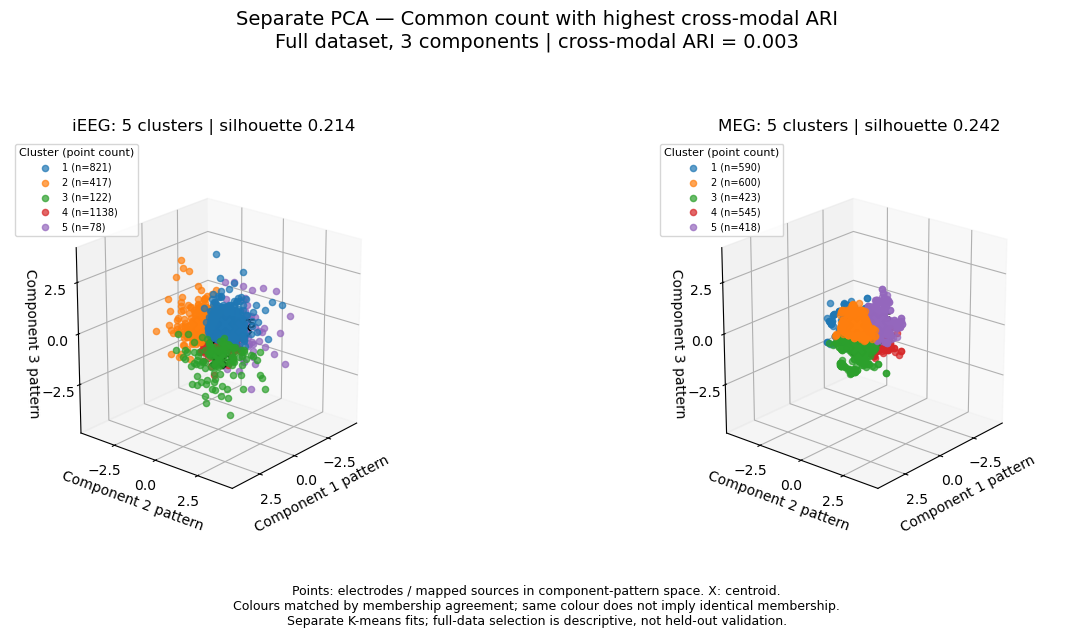

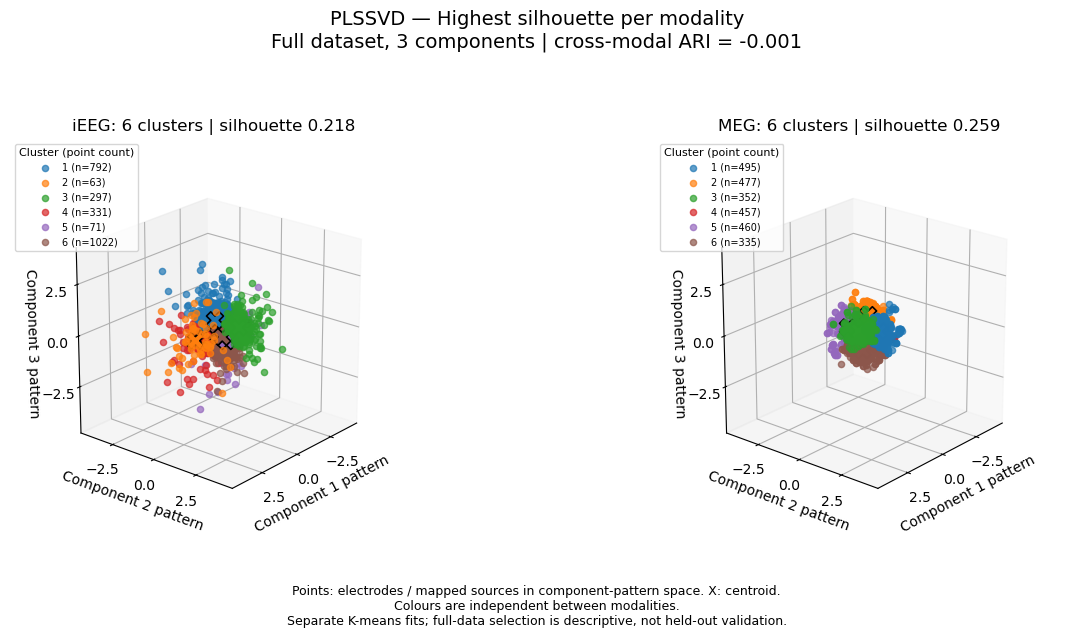

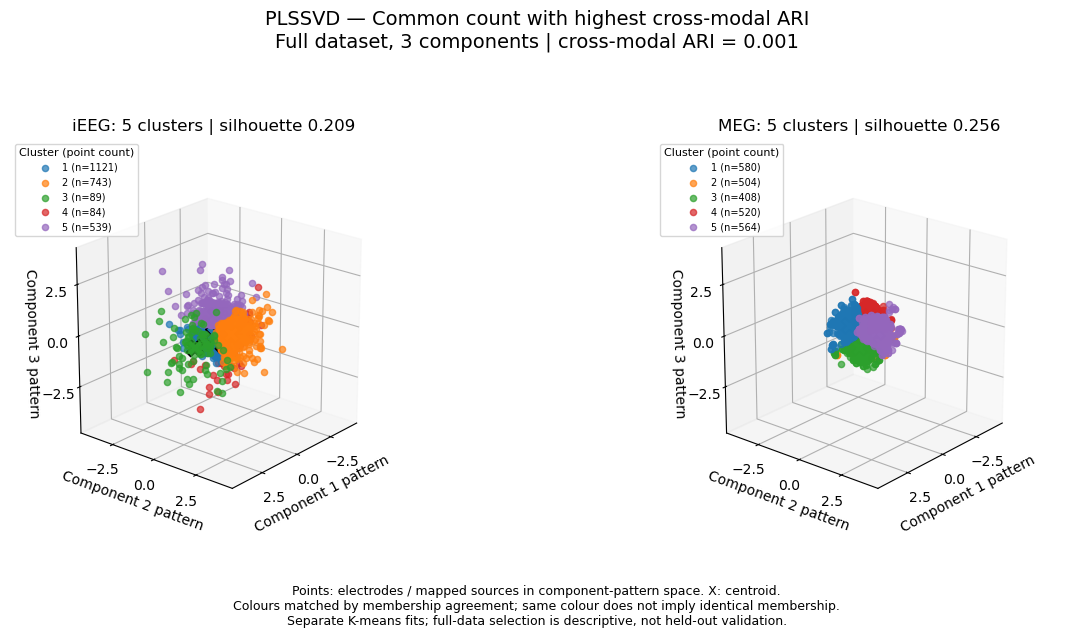

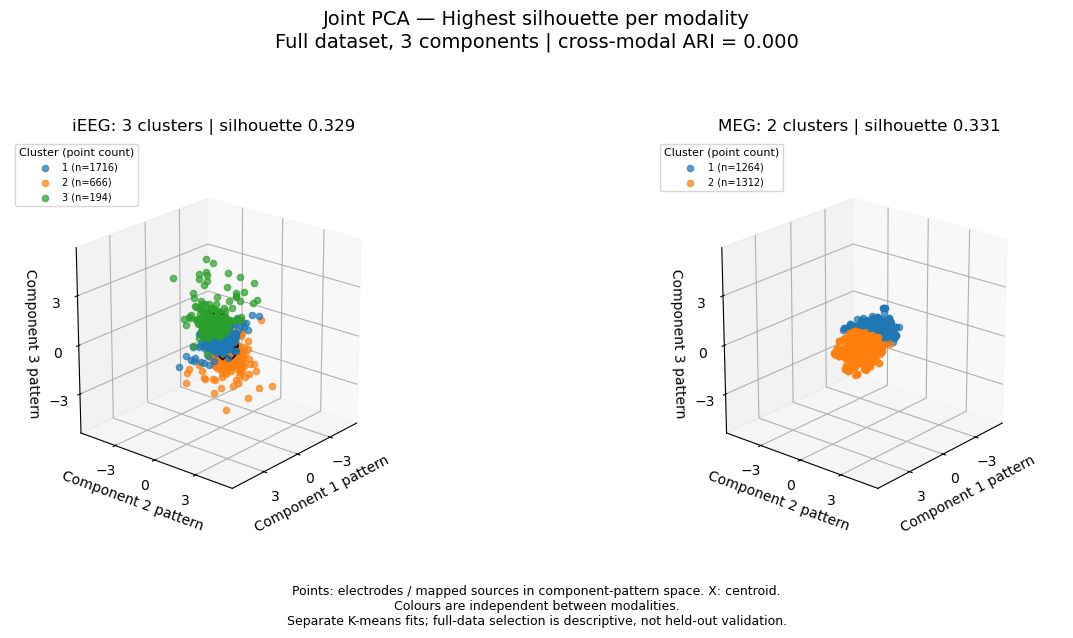

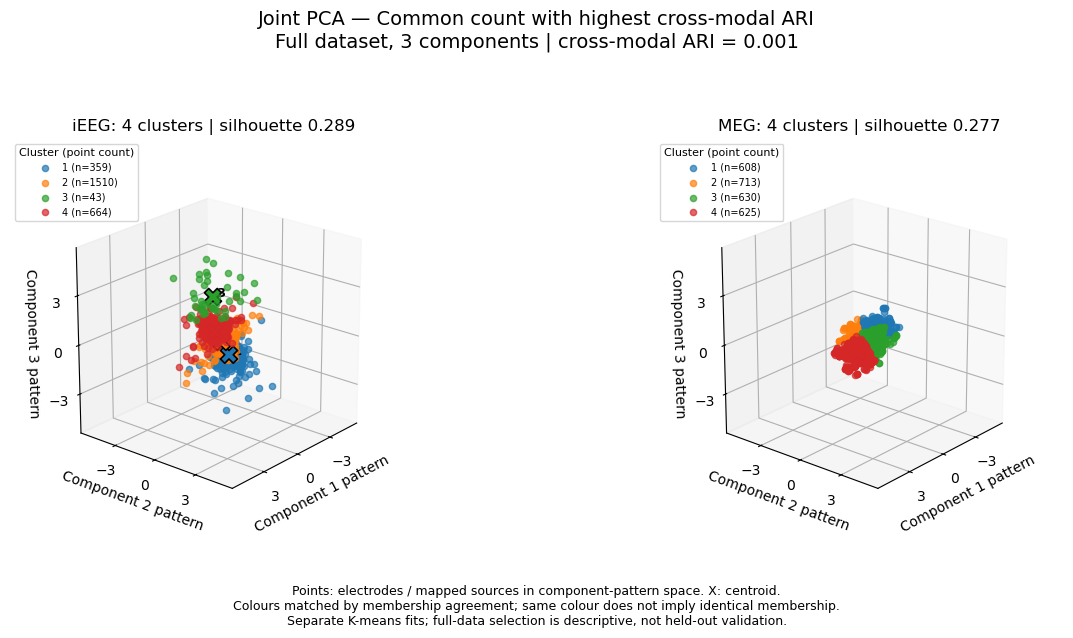

In [6]:
from vs3_0_compare_subspace import plot_full_data_clusters
cluster_paths, cluster_choices = plot_full_data_clusters(OUTPUT_DIR, show=True)
#display(cluster_choices)


### Unpaired native-feature clouds
All native features contribute without electrode/source pairing. Training temporal Procrustes aligns pattern coordinates; training spatial mean and one RMS normalize each modality. Default --cloud-prototypes 32 compresses all features into weighted training groups; fixed membership aggregates test patterns. These are prototype approximations, not exact full-cloud metrics. Increase resolution for sensitivity checks. Equal feature mass is used, not equal participant mass.

Wasserstein W2 uses squared Euclidean transport cost; GW squared loss compares internal distances using a local, nonconvex solver with two starts and saved convergence status; Gaussian MMD² uses a fixed training-distance bandwidth. Lower is closer; these are not p-values. Dashed = full-data, solid = test median, shading = fold range. Artifacts save rotation, memberships, masses, normalization, bandwidth and prototypes.


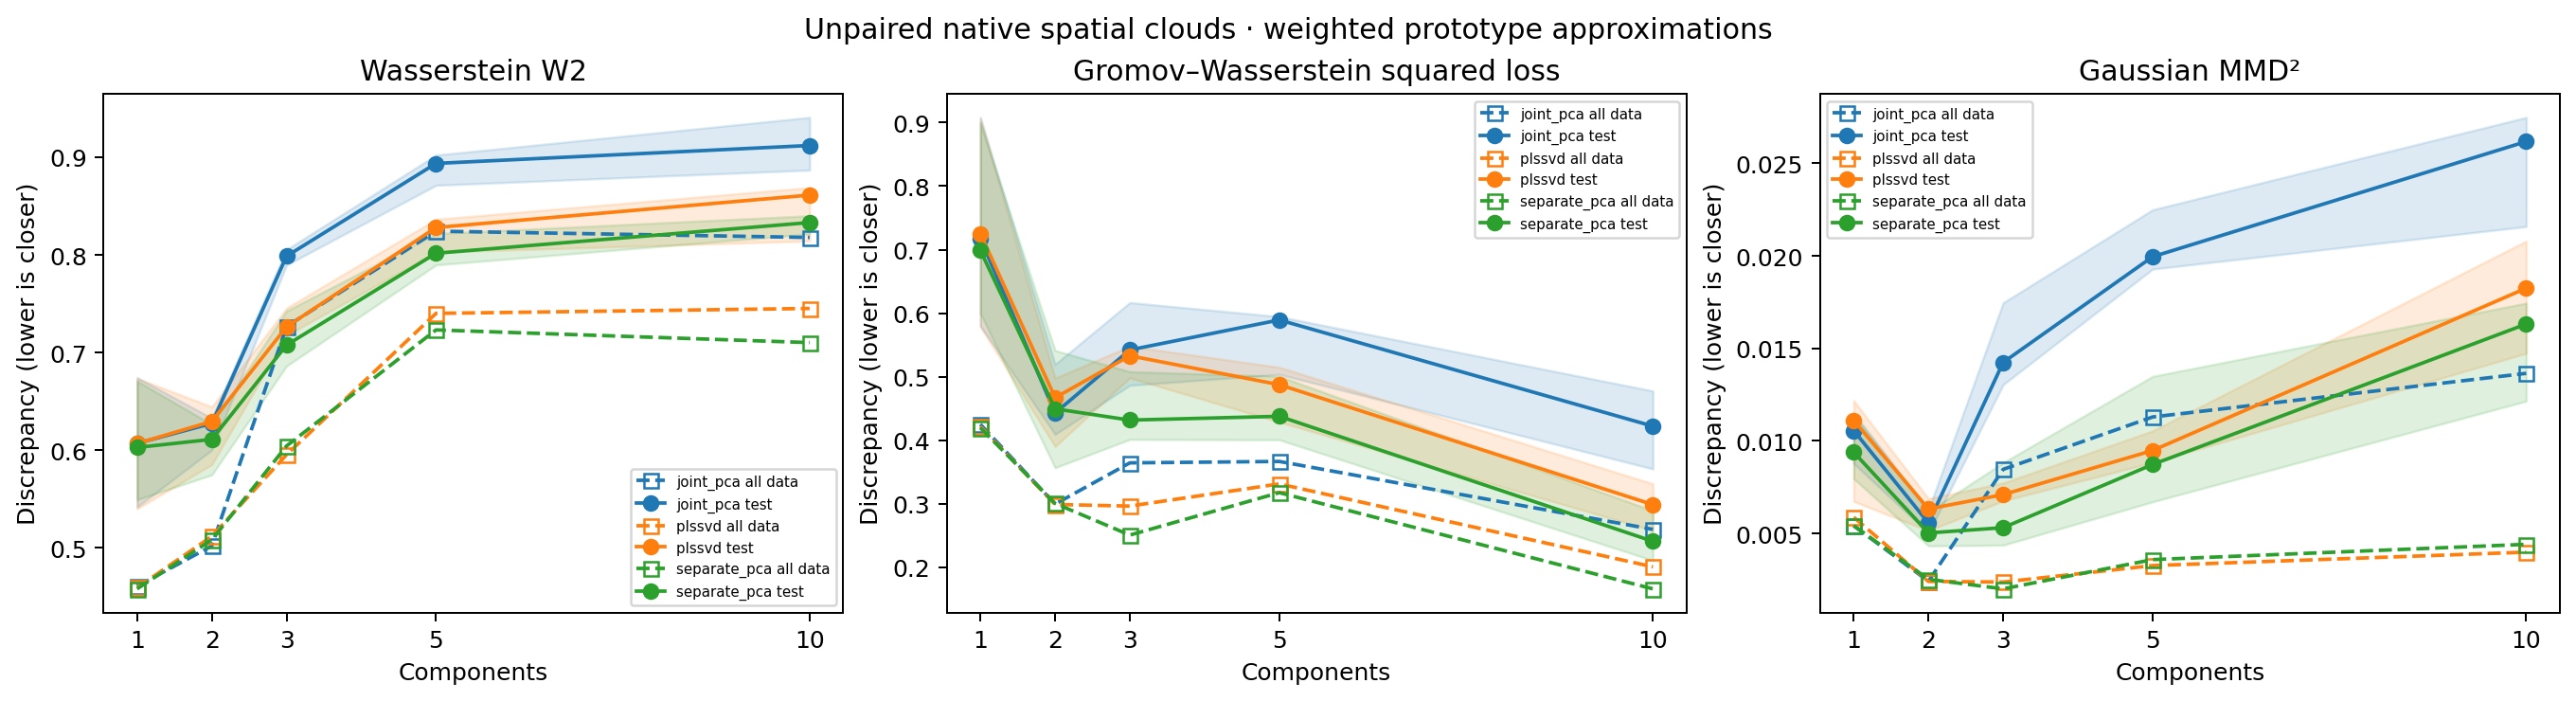

,analysis,model,repeat,k,partition,wasserstein2,gw_squared_loss,mmd2,gw_converged,gw_iterations,ieeg_features,meg_features,ieeg_prototypes,meg_prototypes,mmd_bandwidth
0,in_sample,separate_pca,-1,1,in_sample,0.458065,0.419280,0.005414,True,5,2576,2576,32,32,1.803690
1,in_sample,separate_pca,-1,2,in_sample,0.508268,0.300178,0.002517,True,8,2576,2576,32,32,1.691130
2,in_sample,separate_pca,-1,3,in_sample,0.604379,0.250355,0.002001,True,14,2576,2576,32,32,1.618985
3,in_sample,separate_pca,-1,5,in_sample,0.723185,0.317185,0.003581,True,6,2576,2576,32,32,1.457983
4,in_sample,separate_pca,-1,10,in_sample,0.710202,0.165638,0.004407,True,5,2576,2576,32,32,1.148580
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
160,cross_validation,joint_pca,4,3,train,0.671261,0.279628,0.008675,True,5,2576,2576,32,32,1.607233
161,cross_validation,joint_pca,4,5,test,0.893679,0.589236,0.022493,True,4,2576,2576,32,32,1.418762
162,cross_validation,joint_pca,4,5,train,0.809062,0.311872,0.013141,True,10,2576,2576,32,32,1.418762
163,cross_validation,joint_pca,4,10,test,0.940833,0.385265,0.026178,True,7,2576,2576,32,32,1.243039


In [7]:
# Requires a new completed run of the updated script.
display(Image(filename=str(OUTPUT_DIR / "unpaired_cloud_distances.png")))
display(tables["cloud_metrics"])

## 4. Weight stability: trial-only, pairing-only, and combined variation

Run the controlled analysis on the cluster:
```bash
submit_to_cluster -n 2 -q short.q "python -u vs3_0_weight_stability.py --iterations 100 --components 10"  --project MINDLAB2021_MEG-TempSeqAges
```
Choose k in advance. Each iteration fits separate PCA, PLSSVD and joint PCA on one randomly selected half of the trials per condition. No held-out-quarter or bootstrap analysis is run here. Cross-modal weight correlations below describe covariation across resampling iterations. Completed iterations resume automatically. `--summarize-only` recomputes summaries without fits or atlas access. `--conditions trials pairing both` selects the runs (all three by default).

Optional: `--split-unit group`, coordinate-directory/unit overrides, `--pool-hemispheres`, `--roi-level parcel|region|group` (default `region`). AAL must be cached, or supply `--atlas-image` and `--atlas-labels` with `atlas_id,parcel,region,group` columns for an offline atlas. The output directory is new: previous combined fits do not implement these controlled random streams.

### What each reliability measure tests

- **Trials only:** change the selected half of the trials, keeping MEG–iEEG pairing fixed.
- **Pairing only:** change participant pairing, keeping each participant's selected trials fixed. If the MEG pool is larger, this includes changes in participant inclusion.
- **Both:** change both factors. The trial-selection sequence matches the trial-only run, and the pairing sequence matches the pairing-only run. Iteration zero is identical in all three conditions.

For each condition, display an **iteration × iteration heatmap**, a **bilateral ROI scatter plot**, and **iEEG × MEG ROI mean/SD correlation heatmaps** for each model. Components are matched to iteration zero using training temporal scores; no matching is optimized on spatial weights. Coupled models retain a shared component permutation/sign across modalities. Separate iEEG PCA must remain unchanged in the pairing-only condition.

Heatmaps correlate weight magnitudes across locations: `corr(abs(w_iteration_i), abs(w_iteration_j))`. This measures spatial-pattern consistency, not equality of individual coefficients. Diagonals are masked. The iterations and their pairwise comparisons are not independent replications.

**ROI scatter:** first average absolute weights within each coverage participant/ROI, then average participants equally, separately for every iteration. Plot the mean of these ROI values across iterations with **±1 sample SD across iterations**. Bars are not confidence intervals or within-ROI dispersion across channels. Missing atlas labels are excluded, not set to zero. A small mean and small SD can describe a consistently negligible weight.

Both modalities use fixed iEEG coverage-location ROI labels and participant grouping. This prevents ROI composition from changing with the MEG source assignment. MEG therefore measures stability at matched coverage locations, not identical native MEG sources. Repeated matches remain separate coverage slots. This is not a native-source parcel map.

ROI averages may hide opposing changes in individual channels. `feature_stability.csv` saves each channel/coverage slot's mean and SD. Set `ROI_ERROR = 'mean_channel_sd'` to show the participant-balanced mean of individual-channel SDs as the error bar instead; it is explicitly labelled and is not the SD of the ROI mean. Weights are in the training-preprocessed feature coordinates, including MEG channel z-scoring.


### Cross-modal weight covariation across iterations
For the selected component, compute signed Pearson correlation for every iEEG coverage location $a$ and MEG coverage location $b$, using all saved iterations $I$ (100 when 100 were fitted):

$$r_{ab}=\mathrm{corr}_{i=1,\ldots,I}(w^{\mathrm{iEEG}}_{i,a},w^{\mathrm{MEG}}_{i,b}).$$

For each bilateral ROI pair $(A,B)$, display the arithmetic mean and sample SD of its valid channel-pair correlations:

$$\bar r_{AB}=\frac{1}{N_{AB}}\sum_{a\in A,b\in B}r_{ab},\qquad
s_{AB}=\sqrt{\frac{\sum_{a\in A,b\in B}(r_{ab}-\bar r_{AB})^2}{N_{AB}-1}}.$$

Rows are iEEG ROIs; columns are MEG ROIs. Correlations are computed **before** ROI averaging. These are signed-weight correlations, whereas the existing ROI scatter shows magnitudes. Left/right ROI labels are pooled before grouping. Each valid channel pair has equal weight; these heatmaps are not participant-balanced. Constant or numerically constant trajectories are excluded; undefined values appear gray. The table reports valid and possible pair counts. SD requires at least two valid pairs.

These heatmaps describe whether weights change together **across iterations**, not a correlation time series indexed by iteration. SD is heterogeneity among channel-pair correlations, not SD across iterations, a standard error, or a confidence interval. Pair correlations share channels and are dependent. In pairing-only runs, iEEG trajectories may be constant, making their correlations undefined. MEG rows remain fixed iEEG coverage slots; their assigned native sources may change. Separate PCA axes are aligned within each modality, so cross-modal signs depend on those reference-axis conventions.

Existing saved summaries are upgraded automatically if necessary, using fitted weight files without refitting models. Restarting the kernel is unnecessary: the cell explicitly reloads the plotting module.


In [ ]:
from pathlib import Path
import importlib
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
import vs3_0_weight_stability as weight_stability
importlib.reload(weight_stability)

WEIGHT_OUTPUT = ROOT / 'out' / 'weight_stability' / 'paired_coverage'
WEIGHT_COMPONENT = 3
ROI_ERROR = 'sd_across_iterations'  # alternatively 'mean_channel_sd'

for variation in ('trials', 'pairing', 'both'):
    folder = WEIGHT_OUTPUT / variation
    display(Markdown(f"### {weight_stability.TITLES[variation]} — component {WEIGHT_COMPONENT}"))
    iteration_fig, roi_fig, cross_roi_fig = weight_stability.plot_weight_stability(
        folder, component=WEIGHT_COMPONENT, roi_error=ROI_ERROR)
    for label, figure in (
        ('Spatial-pattern consistency across iterations', iteration_fig),
        ('Mean weight magnitude by bilateral ROI', roi_fig),
        ('iEEG × MEG ROIs: mean and SD of channel-pair correlations across iterations', cross_roi_fig),
    ):
        display(Markdown(f'**{label}**'))
        display(figure)
        plt.close(figure)
    cross_roi = pd.read_csv(folder / 'roi_cross_correlations.csv')
    display(cross_roi.loc[cross_roi.component == WEIGHT_COMPONENT,
        ['model', 'ieeg_roi', 'meg_roi', 'mean_r', 'sd_r',
         'n_pairs', 'n_possible_pairs', 'n_iterations']].round(3))
